<a href="https://colab.research.google.com/github/2d-game-dev/spoken-language-id-cnn/blob/main/AudioCNNProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from datasets import load_dataset
import numpy as np, librosa

langs = ["es_419", "pt_br", "fr_fr", "ru_ru", "ja_jp", "cmn_hans_cn", "ko_kr", "en_us", "nb_no"]


In [3]:
def crop_or_pad(audio, target=48000):  # The goal is equal length (48,000 samples = 3 s)
  if len(audio) > target:
    start = (len(audio) - target) // 2
    return audio[start:start+target]
  else:
    return np.pad(audio, (0, target - len(audio)))
# The middle is where the actual talking almost always is, so the model sees real speech instead of silence.

# Rule of thumb: functions return their result, and you print from outside to check it.
# Inside, print only to watch progress or hunt bugs.

In [4]:
def make_logmel(audio):
    mel = librosa.feature.melspectrogram(y=audio, sr=16000, n_mels=64)
    return librosa.power_to_db(mel, ref=np.max)
# Convert 3 s of audio into a 64x94 log-mel spectrogram:
# an image-like input that shows which frequencies occur over time (CNN input)

In [5]:
counts = {"train": 300, "validation":50, "test": 50}
data = {"train": [], "validation": [], "test": []}

for index, lang_code in enumerate(langs):
   for split, n in counts.items():
       ds = load_dataset("google/fleurs", lang_code, split=split, streaming=True)
       for ex in ds.take(n):                              # loop 3: each clip
            clip = crop_or_pad(ex["audio"]["array"])
            logmel = make_logmel(clip)
            data[split].append((logmel, index))
   print(f"Label {index}: {lang_code} done")
   print(len(data["train"]), len(data["validation"]), len(data["test"]))

README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

Label 0: es_419 done
300 50 50
Label 1: pt_br done
600 100 100
Label 2: fr_fr done
900 150 150
Label 3: ru_ru done
1200 200 200
Label 4: ja_jp done
1500 250 250
Label 5: cmn_hans_cn done
1800 300 300
Label 6: ko_kr done
2100 350 350
Label 7: en_us done
2400 400 400
Label 8: nb_no done
2700 450 450


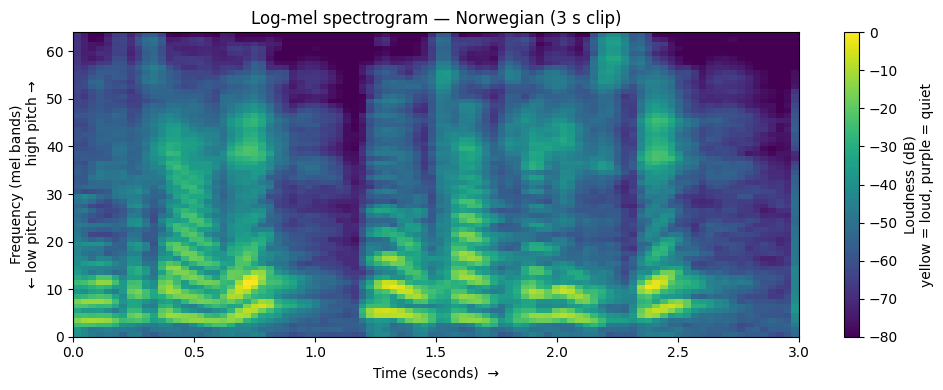

In [6]:
import matplotlib.pyplot as plt

logmel = make_logmel(clip)

plt.figure(figsize=(10, 4))
plt.imshow(logmel, origin="lower", aspect="auto",
           extent=[0, 3, 0, 64])        # x-axis in seconds (0–3), y-axis in mel bands (0–64)

plt.title(f"Log-mel spectrogram — {ex['language']} (3 s clip)")
plt.xlabel("Time (seconds)  →")
plt.ylabel("Frequency (mel bands)\n← low pitch          high pitch →")

cbar = plt.colorbar()
cbar.set_label("Loudness (dB)\nyellow = loud, purple = quiet")

plt.tight_layout()
plt.show()

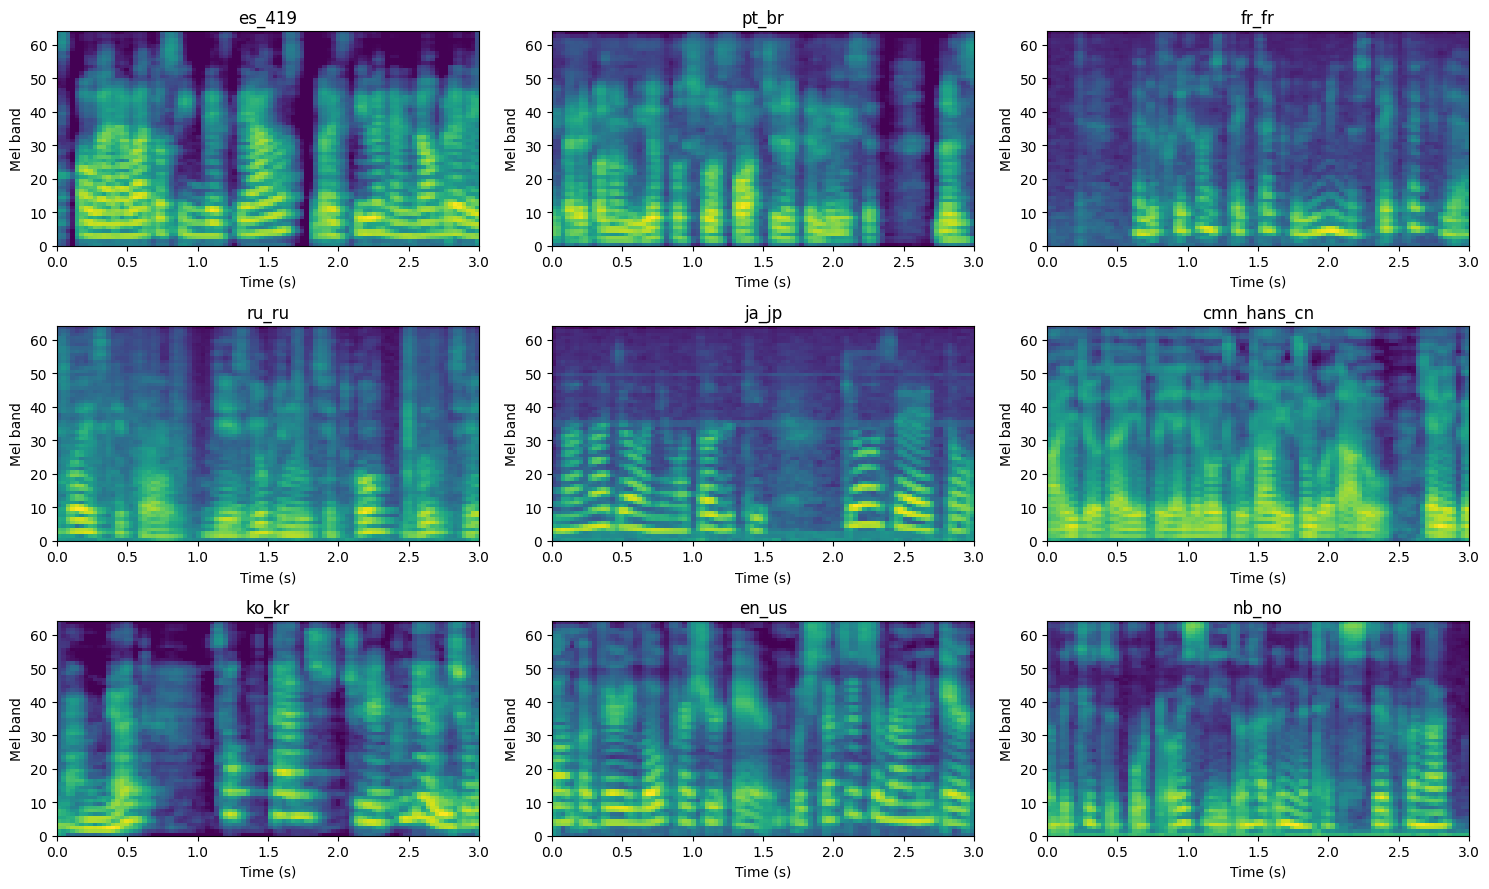

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))   # 3x3 grid of small plots

for index, lang_code in enumerate(langs):
    logmel, label = data["train"][index * counts["train"]]   # first train clip of this language
    ax = axes.flat[index]                                    # pick grid slot 0..8
    ax.imshow(logmel, origin="lower", aspect="auto", extent=[0, 3, 0, 64])
    ax.set_title(lang_code)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Mel band")

plt.tight_layout()
plt.show()

In [8]:
from google.colab import drive
import os
drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/AudioCNNProject"
os.makedirs(save_dir, exist_ok=True)

for split in data:
    X = np.stack([logmel for logmel, label in data[split]])
    y = np.array([label for logmel, label in data[split]])
    np.save(f"{save_dir}/X_{split}.npy", X)
    np.save(f"{save_dir}/y_{split}.npy", y)
    print(split, X.shape, y.shape)

Mounted at /content/drive
train (2700, 64, 94) (2700,)
validation (450, 64, 94) (450,)
test (450, 64, 94) (450,)
